# Comparaison des stratégies de consensus

On garde **le même groupe** et la **même ontologie**, et on fait varier les « briques » du système pour voir leur effet :

1. la **fonction de bien-être** (comment on agrège les satisfactions) ;
2. le **moteur de recherche** (génétique vs exhaustif = vérité-terrain) ;
3. le **critère de consensus** (quand on déclare l'accord) ;
4. le **mode de vote** (binaire vs score 0–10) ;
5. la **variante de veto** (simple / quadratique / coalition).

> Prérequis : `pip install -r requirements.txt`.

## Le groupe de test

On construit un groupe avec une vraie tension : trois personnes aiment la plage, une la ville, et **Ève** ne jure que par la montagne (poids très fort sur le type). Aucune option ne plaît à tout le monde : c'est ce qui révèle les différences entre stratégies.

In [1]:
import numpy as np
import pandas as pd

from simulateur import Personne, CRITERES, charger_catalogue

catalogue = charger_catalogue()

poids_eq = {c: 1 / len(CRITERES) for c in CRITERES}
# Eve : le type pese tres lourd (elle veut la montagne, point).
poids_eve = {"type": 0.60, "localisation": 0.10, "semaine": 0.10, "budget": 0.10, "animation": 0.10}

groupe = [
    Personne("Alice", "Plage", "Espagne", {30, 31, 32, 33}, 800, 8, poids_eq, marge=0.2, credits_veto=2),
    Personne("Bob",   "Plage", "Espagne", {30, 31, 32, 33}, 800, 7, poids_eq, marge=0.2, credits_veto=2),
    Personne("Carol", "Plage", "France",  {29, 30, 31, 32}, 700, 6, poids_eq, marge=0.2, credits_veto=2),
    Personne("David", "Ville", "Italie",  {30, 31, 32, 33}, 800, 8, poids_eq, marge=0.2, credits_veto=2),
    Personne("Eve",   "Montagne", "Suisse", {27, 28, 29, 30}, 1200, 3, poids_eve, marge=0.2, credits_veto=2),
]
print(f"{len(groupe)} votants, {len(catalogue)} destinations.")

5 votants, 12 destinations.


## 1. Fonctions de bien-être

Pour chaque philosophie d'agrégation, on cherche (par **moteur exhaustif**, donc l'optimum exact) le séjour qui la maximise, et on regarde les satisfactions obtenues. L'**utilitariste** (moyenne) maximise le total quitte à léser quelqu'un ; les approches **égalitaristes** (min, Nash, leximin) remontent le plus malheureux.

In [2]:
from strategies import BIENS_ETRE, meilleur_exhaustif

lignes = []
for nom, fonction in BIENS_ETRE.items():
    res = meilleur_exhaustif(catalogue, groupe, bien_etre=fonction)
    sats = res["satisfactions"]
    valeurs = list(sats.values())
    lignes.append({
        "bien-etre": nom,
        "sejour": f"{res['attrs']['nom']} ({res['attrs']['type']})",
        "moyenne": round(np.mean(valeurs), 2),
        "min": round(min(valeurs), 2),
        **sats,
    })

pd.DataFrame(lignes).set_index("bien-etre")

,sejour,moyenne,min,Alice,Bob,Carol,David,Eve
bien-etre,,,,,,,,
moyenne,Costa Brava (Plage),0.79,0.41,1.00,0.98,0.84,0.72,0.41
min,Annecy (Montagne),0.75,0.66,0.66,0.68,0.82,0.66,0.92
mixte,Annecy (Montagne),0.75,0.66,0.66,0.68,0.82,0.66,0.92
nash,Costa Brava (Plage),0.79,0.41,1.00,0.98,0.84,0.72,0.41
leximin,Annecy (Montagne),0.75,0.66,0.66,0.68,0.82,0.66,0.92


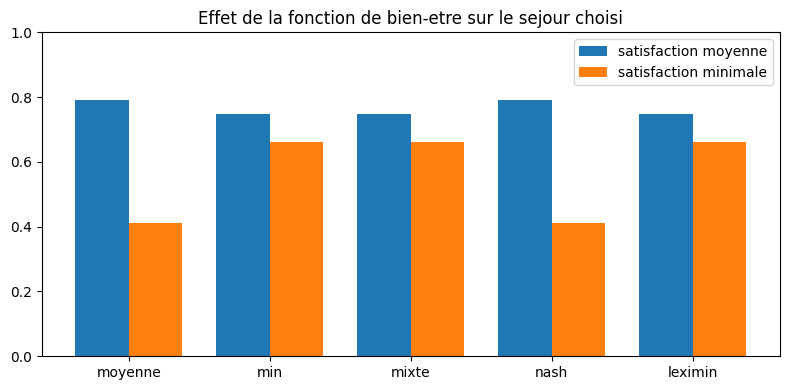

In [3]:
import matplotlib.pyplot as plt

noms = list(BIENS_ETRE.keys())
moys, mins = [], []
for fonction in BIENS_ETRE.values():
    s = list(meilleur_exhaustif(catalogue, groupe, bien_etre=fonction)["satisfactions"].values())
    moys.append(np.mean(s))
    mins.append(min(s))

x = np.arange(len(noms))
largeur = 0.38
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x - largeur / 2, moys, largeur, label="satisfaction moyenne")
ax.bar(x + largeur / 2, mins, largeur, label="satisfaction minimale")
ax.set_xticks(x)
ax.set_xticklabels(noms)
ax.set_ylim(0, 1)
ax.set_title("Effet de la fonction de bien-etre sur le sejour choisi")
ax.legend()
fig.tight_layout();

## 2. Moteur génétique vs exhaustif (vérité-terrain)

L'espace ne fait que ~88 candidats : on peut donc tout évaluer et obtenir l'**optimum exact**. C'est une excellente façon de vérifier que l'algorithme génétique ne se trompe pas. On compare, pour chaque bien-être, le séjour trouvé par le GA et l'optimum exhaustif.

In [4]:
from consensus_ga import meilleur_candidat_ga

lignes = []
for nom, fonction in BIENS_ETRE.items():
    ex = meilleur_exhaustif(catalogue, groupe, bien_etre=fonction)
    ga = meilleur_candidat_ga(catalogue, groupe, bien_etre=fonction, graine=0)
    lignes.append({
        "bien-etre": nom,
        "exhaustif": f"{ex['attrs']['nom']} (s{ex['attrs']['semaine']})",
        "genetique": f"{ga.attrs['nom']} (s{ga.attrs['semaine']})",
        "GA == optimum ?": ex["candidat"] == ga.candidat,
    })

pd.DataFrame(lignes).set_index("bien-etre")

,exhaustif,genetique,GA == optimum ?
bien-etre,,,
moyenne,Costa Brava (s30),Costa Brava (s30),True
min,Annecy (s30),Annecy (s30),True
mixte,Annecy (s30),Annecy (s30),True
nash,Costa Brava (s30),Costa Brava (s30),True
leximin,Annecy (s30),Annecy (s30),True


## 3. Critère de consensus

On lance le protocole complet en changeant **uniquement la condition d'arrêt**. Un critère strict (unanimité) demande plus de rounds — ou échoue ; un critère souple (majorité, entropie faible) converge plus vite, mais peut laisser des mécontents.

In [5]:
from consensus_ga import rechercher_consensus
from strategies import (
    critere_unanimite, critere_supermajorite, critere_majorite,
    critere_plancher, critere_entropie,
)

criteres = {
    "unanimite": critere_unanimite(),
    "supermajorite (75%)": critere_supermajorite(0.75),
    "majorite (>50%)": critere_majorite(),
    "plancher (min>=0.4)": critere_plancher(0.4),
    "entropie (<=0.2)": critere_entropie(0.2),
}

lignes = []
for nom, crit in criteres.items():
    r = rechercher_consensus(catalogue, groupe, critere_consensus=crit, graine=0, max_rounds=20)
    s = list(r.satisfactions.values())
    lignes.append({
        "critere": nom,
        "sejour": f"{r.attrs['nom']} (s{r.attrs['semaine']})",
        "consensus": r.consensus,
        "rounds": r.nb_rounds,
        "moyenne": round(np.mean(s), 2),
        "min": round(min(s), 2),
    })

pd.DataFrame(lignes).set_index("critere")

,sejour,consensus,rounds,moyenne,min
critere,,,,,
unanimite,Annecy (s30),True,3,0.75,0.66
supermajorite (75%),Annecy (s30),True,3,0.75,0.66
majorite (>50%),Annecy (s30),True,3,0.75,0.66
plancher (min>=0.4),Annecy (s30),True,1,0.75,0.66
entropie (<=0.2),Annecy (s30),True,3,0.75,0.66


## 4. Mode de vote : binaire vs score

En **binaire**, chacun dit oui/non (seuil d'acceptation) et on vise l'unanimité. En **score**, chacun note de 0 à 10 et on déclare l'accord quand le **score moyen** dépasse 6/10 : plus nuancé, on capte l'intensité des préférences plutôt qu'un simple oui/non.

In [6]:
from strategies import critere_score_moyen

r_bin = rechercher_consensus(
    catalogue, groupe, mode_vote="binaire",
    critere_consensus=critere_unanimite(), graine=0, max_rounds=20,
)
r_score = rechercher_consensus(
    catalogue, groupe, mode_vote="score",
    critere_consensus=critere_score_moyen(0.6), graine=0, max_rounds=20,
)

for libelle, r in [("binaire + unanimite", r_bin), ("score + moyenne>=6/10", r_score)]:
    s = list(r.satisfactions.values())
    print(f"{libelle:24s} -> {r.attrs['nom']} (s{r.attrs['semaine']}) | "
          f"consensus={r.consensus} en {r.nb_rounds} rounds | "
          f"moyenne {np.mean(s):.2f}, min {min(s):.2f}")

binaire + unanimite      -> Annecy (s30) | consensus=True en 3 rounds | moyenne 0.75, min 0.66
score + moyenne>=6/10    -> Annecy (s30) | consensus=True en 1 rounds | moyenne 0.75, min 0.66


## 5. Variantes de veto

On reprend un groupe volontairement explosif (**plage / montagne / ville**) et on compare trois mécanismes de blocage :

- **simple** : chaque veto coûte 1 crédit ;
- **quadratique** : le n-ième veto d'une personne coûte n points (le blocage répété devient cher) ;
- **coalition** : un veto ne « passe » que si au moins *k* personnes bloquent ensemble (protège du blocage individuel).

In [7]:
poids_type = {"type": 0.85, "localisation": 0.04, "semaine": 0.05, "budget": 0.03, "animation": 0.03}
groupe3 = (
    [Personne(n, "Plage", "Espagne", {30, 31, 32, 33}, 800, 8, poids_type, marge=0.15, credits_veto=3)
     for n in ("Lou", "Manon")]
    + [Personne(n, "Montagne", "Suisse", {27, 28, 29, 30}, 1200, 3, poids_type, marge=0.15, credits_veto=3)
       for n in ("Tom", "Zoe")]
    + [Personne(n, "Ville", "Italie", {30, 31, 32, 33}, 800, 7, poids_type, marge=0.15, credits_veto=3)
       for n in ("Ali", "Bea")]
)

lignes = []
for mode in ("simple", "quadratique", "coalition"):
    r = rechercher_consensus(
        catalogue, groupe3, mode_veto=mode, k_coalition=3,
        graine=1, max_rounds=25,
    )
    nb_vetos = sum(len(h["vetos_du_round"]) for h in r.historique)
    explores = {tuple(h["leader"]) for h in r.historique}
    lignes.append({
        "mode de veto": mode,
        "sejour final": f"{r.attrs['nom']} ({r.attrs['type']})",
        "consensus": r.consensus,
        "rounds": r.nb_rounds,
        "total vetos poses": nb_vetos,
        "candidats explores": len(explores),
    })

pd.DataFrame(lignes).set_index("mode de veto")

,sejour final,consensus,rounds,total vetos poses,candidats explores
mode de veto,,,,,
simple,Nice (Plage),True,11,18,6
quadratique,Annecy (Montagne),True,11,12,5
coalition,Marrakech (Ville),True,11,12,4


## En résumé

- **Bien-être** : choisir la fonction d'agrégation, c'est choisir une *éthique* (efficacité vs équité). Le `min`, Nash et leximin protègent la personne la plus lésée ; la moyenne maximise le total.
- **GA vs exhaustif** : sur ce petit espace, le génétique retrouve l'optimum exact — utile à vérifier avant de faire confiance à une métaheuristique sur de plus gros problèmes.
- **Critère de consensus** : c'est le curseur entre légitimité (unanimité) et rapidité (majorité/entropie). À régler selon l'enjeu.
- **Mode de vote** : le score capte l'intensité des préférences, là où le binaire perd de l'information.
- **Veto** : rendre le blocage *coûteux* (quadratique) ou *collectif* (coalition) évite qu'une personne paralyse le groupe.

Toutes ces briques sont des paramètres de `rechercher_consensus` (voir `strategies.py`) : on peut les recombiner librement.